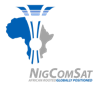 &nbsp;&nbsp; 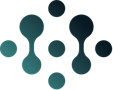

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-6/day-1-backtesting/4-instructor-only/W6D1-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🔁 Week 6 · Day 1: Backtesting: Test It on the Past First

**Today:** you expose a lucky score, replay the Week 5 forecasts on the past many times (a **backtest**), and decide which forecast the NOC should use for next week and for next month's roster.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W6D1-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _c_a1(x):
    return _near(x, 7.7734375, 0.01), \
        f"{float(x):.2f}: the flat average beat all four code-book baselines on these 8 weeks. Genius… or one lucky screenshot? 📸", \
        "The flat average of the training weeks: train.mean()"

def _c_a2(x):
    n, m = x
    return int(n) == 45 and _near(m, 16.495209949289585, 0.01), \
        f"{int(n)} origins, mean MAE {float(m):.2f}: over the full record the 'genius' is the worst of all. One split is one screenshot. 🙈", \
        "The lucky split forecast 8 weeks ahead: H_AHEAD = 8"

def _c_b1(x):
    v = [round(float(a), 4) for a in x]
    want = [2.4637, 4.6724, 2.8148, 1.2733, 7.6718, 5.149]
    return len(v) == len(want) and all(abs(a - b) < 0.01 for a, b in zip(v, want)), \
        f"Six folds: {', '.join(f'{a:.2f}' for a in v)}. Six exams, not one. 🚶🏾", \
        "The code book slides 4 weeks each time and scores 4 weeks: STEP = 4, H_FOLD = 4"

def _c_b2(x):
    m, w = x
    return _near(m, 4.007504893794342, 0.01) and pd.Timestamp(w) == pd.Timestamp('2025-10-20'), \
        f"Mean {float(m):.2f}, worst fold starts 20 Oct: it contains 3 November, when the rains end. Report the spread AND when. 🌦️", \
        "MEAN = fold_mae.mean() and WORST_FOLD = folds[\"regression\"].idxmax()"

def _c_c1(x):
    v = [round(float(a), 4) for a in x]
    want = [2.0, 1.75, 1.0, 1.0, 6.75, 6.25]
    return len(v) == len(want) and all(abs(a - b) < 0.01 for a, b in zip(v, want)), \
        "Naive, made the same way as the regression: each week = last week's real count. Mean 3.12. 👵🏾", \
        "One-step naive is the column that holds last week's count: NAIVE_COLUMN = \"tickets_lag1\""

def _c_c2(x):
    return int(x) == 5, \
        "5 of 6: Grandma beats the regression on five folds. It only wins the 17 Nov fold (the December jump). 👵🏾🏆", \
        "Count the folds where naive's MAE is smaller: int((folds[\"naive\"] < folds[\"regression\"]).sum())"

def _c_c3(x):
    m, w = x
    return _near(m, 2.6479801867313486, 0.01) and _near(w, np.float64(2.008767079572676), 0.01), \
        f"Mean {float(m):.2f}, the lowest, and {float(w):.2f} on the season-change fold, forecasting all 4 weeks blind. 🧮", \
        "The rate forecast is made once per fold, for the whole fold: RATE_H = 4"

def _c_d1(x):
    t = x
    ok = list(t.index) == [1, 4, 8] and all(_near(t.loc[h, k], v, 0.01) for h, k, v in (
        (1, "naive", 3.1923076923076925), (1, "rate_seasonal_naive", 3.2892121149245503), (4, "naive", 5.025510204081633),
        (4, "rate_seasonal_naive", 3.207988173312929), (8, "naive", 6.2), (8, "rate_seasonal_naive", 3.1801353620382873)))
    return ok, "Naive: 3.19 → 5.03 → 6.20 as you look further ahead. Rate: 3.29 → 3.21 → 3.18. Grandma tires; the rate forecast doesn't. 🏃🏾", \
        "Three horizons, in weeks, as a list: HORIZONS = [1, 4, 8]"

def _c_d2(x):
    a, b = (str(v).strip() for v in x)
    return a == "naive" and b == "rate_seasonal_naive", \
        "1 week ahead: naive, by a hair over the rate forecast. 8 weeks ahead: the rate forecast, by a mile. The horizon decides. 🔭", \
        "Lowest number in each row: BEST_1 = summary.loc[1].idxmin(), BEST_8 = summary.loc[8].idxmin()"

def _c_e1(x):
    return int(x) == 4, \
        "4: the roster needs 4 weeks ahead. The regression can't run that far, and naive's error grows. Rate seasonal naive. ✅", \
        "The roster is 4 weeks out. Which method can forecast 4 weeks blind, with the lowest error in Part D?"

def _c_bonus(x):
    return _near(x, 2.960193306931992, 0.01), \
        f"{float(x):.2f} vs naive 3.16: refit every week and the regression edges ahead (13 weeks to 12). The rate forecast scores 2.69 on the same weeks, and it's the only one that works 8 weeks out. A design choice moved the result: fix yours BEFORE you look. 🌶️", \
        "Refit every week, forecast one week: STEP_EVERY = 1"

CHECKS = {"A1": _c_a1, "A2": _c_a2, "B1": _c_b1, "B2": _c_b2, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3,
          "D1": _c_d1, "D2": _c_d2, "E1": _c_e1, "BONUS": _c_bonus}
HINTS = {"A2": "H_AHEAD is a number of weeks.", "B1": "STEP and H_FOLD are numbers of weeks.",
         "B2": "MEAN is a number; WORST_FOLD is the date the worst fold starts.", "D1": "HORIZONS is a list of numbers.",
         "D2": "Two method names, as text, from the summary table's columns.", "E1": "A number from 1 to 4."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


### ▶️ The data
The same weekly NOC ticket file as Week 5 Days 2 and 3: tickets raised each week, and how many VSAT terminals were live.

In [ ]:
from sklearn.linear_model import LinearRegression

tickets = pd.read_csv(data_path("ops_tickets_weekly"), parse_dates=["week_start"],
                      index_col="week_start").asfreq("W-MON")
print("weeks:", len(tickets), "· from", tickets.index[0].date(), "to", tickets.index[-1].date(),
      "· gaps:", int(tickets.isna().sum().sum()))
tickets.tail(3)

### ▶️ Your tools from Week 5 (run all three cells)
The baselines and the MAE scorer (Week 5 Day 2), the feature table (Week 5 Day 3), and today's two backtest functions. Read them once, then run.

In [ ]:
def naive(series, h):
    """Grandma's forecast: the last value we saw, repeated h times."""
    return np.full(h, float(series.iloc[-1]))

def seasonal_naive(series, h, period=52):
    """The same weeks one season (52 weeks) ago."""
    last_season = series.iloc[-period:].values
    return np.tile(last_season, int(np.ceil(h / period)))[:h].astype(float)

def moving_average(series, h, window=8):
    """The mean of the last `window` weeks, held flat."""
    return np.full(h, float(series.iloc[-window:].mean()))

def exp_smoothing(series, h, alpha=0.3):
    """Simple exponential smoothing: a running level, each new week pulls it alpha of the way."""
    level = series.iloc[0]
    for v in series.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return np.full(h, float(level))

def rate_seasonal_naive(series, terminals, h, period=52):
    """Grandma, adjusted for the bigger family: last year's tickets PER TERMINAL x today's terminals."""
    rate = series / terminals
    return rate.iloc[-period:].values[:h] * float(terminals.iloc[-1])

def mae(forecast, actual):
    """Mean absolute error: on a typical week, how many tickets were we off by?"""
    return float(np.mean(np.abs(np.asarray(forecast, float) - np.asarray(actual, float))))

print("✅ naive, seasonal_naive, moving_average, exp_smoothing, rate_seasonal_naive, mae: ready")

In [ ]:
def make_features(df):
    """The code book's feature table. Every column is known BEFORE the week starts."""
    f = pd.DataFrame(index=df.index)
    f["tickets_lag1"] = df["tickets_raised"].shift(1)     # last week (shift(+1) = the past)
    f["tickets_lag52"] = df["tickets_raised"].shift(52)   # same week, last year
    f["terminals"] = df["active_vsat_terminals"]
    woy = df.index.isocalendar().week.astype(int)
    f["sin52"] = np.sin(2 * np.pi * woy / 52)             # week of year as a smooth circle
    f["cos52"] = np.cos(2 * np.pi * woy / 52)
    f["target"] = df["tickets_raised"]
    return f.dropna()

def walk_forward_errors(feat, x_cols, first=12):
    """Honest past misses: for each week from row `first`, fit on the rows BEFORE it, forecast it, keep the miss."""
    errors = []
    for k in range(first, len(feat)):
        model = LinearRegression().fit(feat[x_cols].iloc[:k], feat["target"].iloc[:k])
        errors.append(feat["target"].iloc[k] - model.predict(feat[x_cols].iloc[[k]])[0])
    return np.array(errors)

def rate_past_errors(df, origin, h=8, period=52):
    """Misses of every h-week rate forecast made from an earlier origin whose h weeks end before `origin`."""
    errors = []
    for o in range(period, origin - h + 1):
        f = rate_seasonal_naive(df["tickets_raised"].iloc[:o], df["active_vsat_terminals"].iloc[:o], h, period)
        errors.extend(df["tickets_raised"].iloc[o:o + h].values - f)
    return np.array(errors)

X_COLS = ['tickets_lag1', 'tickets_lag52', 'terminals', 'sin52', 'cos52']
print("✅ make_features and X_COLS: ready")

In [ ]:
def walk_forward_mae(df, feature_fn, x_cols, start_frac=0.5, step=4, h=4):
    """The code book's expanding-window backtest: refit at each cut, forecast h weeks, score, slide forward."""
    feat_all = feature_fn(df)
    n = len(feat_all)
    errors = []
    for cut in range(int(n * start_frac), n - h, step):
        tr, te = feat_all.iloc[:cut], feat_all.iloc[cut:cut + h]
        model = LinearRegression().fit(tr[x_cols], tr["target"])
        errors.append(mae(model.predict(te[x_cols]), te["target"]))
    return np.array(errors)

def rolling_origin(df, forecasters, h, first=52):
    """Stand at EVERY week from `first` on, forecast the next h weeks with each method, score each one."""
    rows = []
    for o in range(first, len(df) - h + 1):
        past, future = df.iloc[:o], df["tickets_raised"].iloc[o:o + h]
        row = {"origin": df.index[o]}
        for name, fn in forecasters.items():
            row[name] = mae(fn(past, h), future)
        rows.append(row)
    return pd.DataFrame(rows).set_index("origin")

print("✅ walk_forward_mae and rolling_origin: ready")

---
# Part A: Expose the lucky split (10 min) 📸

📖 In Week 5 Day 2 we held out the **last 8 weeks** and scored four baselines on them. Let's add a fifth contender that nobody would bet on: the **flat average** of every training week.

### A1 ✍️ The flat training mean
Make an 8-week forecast that is the training average, repeated: replace `___` with the average of `train`.

In [ ]:
H = 8
train, actual = tickets["tickets_raised"].iloc[:-H], tickets["tickets_raised"].iloc[-H:]
board = pd.Series({
    "naive": mae(naive(train, H), actual),
    "seasonal_naive": mae(seasonal_naive(train, H), actual),
    "moving_average": mae(moving_average(train, H), actual),
    "exp_smoothing": mae(exp_smoothing(train, H), actual),
})

flat = train.mean()

assert flat is not None, "✍️ Fill in flat first."
mean_forecast = np.full(H, flat)
board["training_mean"] = mae(mean_forecast, actual)
display(board.sort_values().round(2).to_frame("MAE, last 8 weeks"))
check("A1", board["training_mean"])

### A2 ✍️ The full record
📖 `rolling_origin()` stands at **every** week of the second year, uses only the weeks before it, forecasts the next `h` weeks and scores them.
Each forecaster is a small function: it gets `past` (the weeks before the origin) and `h`, and returns `h` numbers.

✍️ Set `H_AHEAD` to the same horizon as the lucky split (how many weeks did A1 forecast?).

In [ ]:
forecasters_a = {
    "naive": lambda past, h: naive(past["tickets_raised"], h),
    "training_mean": lambda past, h: np.full(h, past["tickets_raised"].mean()),
}

H_AHEAD = 8

assert H_AHEAD is not None, "✍️ Fill in H_AHEAD first."
many = rolling_origin(tickets, forecasters_a, h=H_AHEAD)
print("origins:", len(many))
display(many.mean().round(2).to_frame("mean MAE over every origin"))
check("A2", (len(many), many["training_mean"].mean()))

▶️ One score per origin. The flat mean's lucky week is in there, but so are all its terrible ones.

In [ ]:
assert "many" in globals(), "✍️ Finish A2 first, then run this cell."
ax = many.plot(figsize=(11, 3.6), title="MAE of each 8-week forecast, one point per origin")
ax.set_ylabel("MAE (tickets/week)")
plt.tight_layout()
plt.show()

---
# Part B: Walk the regression forward (15 min) 🚶🏾

📖 The code book's walk-forward backtest for the Week 5 Day 3 regression: start halfway through the feature table, **refit** on everything before the cut, forecast the next weeks, score, slide on.

### B1 ✍️ Six folds
The code book slides **4 weeks** at a time and scores **4 weeks** per fold. Fill in `STEP` and `H_FOLD`.

In [ ]:
STEP = 4
H_FOLD = 4

assert STEP is not None and H_FOLD is not None, "✍️ Fill in STEP and H_FOLD first."
fold_mae = walk_forward_mae(tickets, make_features, X_COLS, step=STEP, h=H_FOLD)

feat_all = make_features(tickets)
n = len(feat_all)
cuts = list(range(int(n * 0.5), n - H_FOLD, STEP))
folds = pd.DataFrame({"fold_start": [feat_all.index[c] for c in cuts], "train_weeks": cuts,
                      "regression": fold_mae}).set_index("fold_start")
display(folds.round(2))
check("B1", fold_mae)

### B2 ✍️ The spread, and when it goes wrong
Fill in the **mean** of the six fold MAEs, and the **start date of the worst fold** (`idxmax()` gives the index label of the biggest value).

In [ ]:
assert "folds" in globals(), "✍️ Finish B1 first, then run this cell."

MEAN = fold_mae.mean()
WORST_FOLD = folds["regression"].idxmax()

assert MEAN is not None and WORST_FOLD is not None, "✍️ Fill in MEAN and WORST_FOLD first."
print(f"mean {MEAN:.2f} · best fold {fold_mae.min():.2f} · worst fold {fold_mae.max():.2f}, starting {pd.Timestamp(WORST_FOLD):%d %b %Y}")
check("B2", (MEAN, WORST_FOLD))

▶️ What happened in the worst fold? Look at the weeks around the start of November.

In [ ]:
assert "folds" in globals(), "✍️ Finish B1 first, then run this cell."
print(tickets.loc["2025-10-13":"2025-11-17", "tickets_raised"].to_frame()
      .assign(change_from_last_week=lambda t: t["tickets_raised"].diff()))
ax = folds["regression"].plot(kind="bar", color="#0A5DB4", title="Regression MAE by fold")
ax.set_xticklabels([f"{t:%d %b}" for t in folds.index], rotation=0)
ax.set_ylabel("MAE (tickets/week)")
plt.tight_layout()
plt.show()

---
# Part C: Same folds for the baselines (15 min) 🥊

📖 A model score means nothing on its own. Score the baselines on **exactly the same weeks**.

The regression gets last week's real count every week, so the fair naive does too: each week's forecast is the week before's real count. That's already a column in the feature table.

### C1 ✍️ One-step naive on every fold
Type the name of the feature-table column that holds **last week's ticket count** (look at `make_features`).

In [ ]:
assert "folds" in globals(), "✍️ Finish Part B first, then run this cell."

NAIVE_COLUMN = "tickets_lag1"

assert NAIVE_COLUMN is not None, "✍️ Fill in NAIVE_COLUMN first."
rows = []
for c in cuts:
    te = feat_all.iloc[c:c + 4]
    rows.append({"fold_start": te.index[0],
                 "naive": mae(te[NAIVE_COLUMN], te["target"]),            # last week, one step ahead
                 "seasonal_naive": mae(te["tickets_lag52"], te["target"])})  # same week last year
folds = folds[["train_weeks", "regression"]].join(pd.DataFrame(rows).set_index("fold_start"))
display(folds.round(2))
check("C1", folds["naive"])

### C2 ✍️ Who wins more folds?
Count the folds where naive's MAE is **smaller** than the regression's. (`(a < b)` gives True/False for each fold; `.sum()` counts the Trues.)

In [ ]:
assert "folds" in globals() and "naive" in folds, "✍️ Finish C1 first, then run this cell."

naive_wins = int((folds["naive"] < folds["regression"]).sum())

assert naive_wins is not None, "✍️ Fill in naive_wins first."
print("naive beats the regression on", int(naive_wins), "of", len(folds), "folds")
display(folds[["regression", "naive", "seasonal_naive"]].mean().round(2).to_frame("mean MAE"))
check("C2", naive_wins)

### C3 ✍️ Add the rate forecast (blind!)
📖 Week 5 Day 2's trick: last year's tickets **per terminal** × today's terminals. Here it stands at the **start** of each fold and forecasts the whole fold in one go: no peeking at any week inside the fold.

✍️ How many weeks must it forecast, from the start of a fold? Fill in `RATE_H`.

In [ ]:
assert "folds" in globals() and "naive" in folds, "✍️ Finish C1 first, then run this cell."

RATE_H = 4

assert RATE_H is not None, "✍️ Fill in RATE_H first."
rate_col = []
for c in cuts:
    o = tickets.index.get_loc(feat_all.index[c])          # the origin: the first week of the fold
    past = tickets.iloc[:o]                                 # only the weeks BEFORE it
    f = rate_seasonal_naive(past["tickets_raised"], past["active_vsat_terminals"], RATE_H)
    rate_col.append(mae(f, feat_all["target"].iloc[c:c + 4]))
folds["rate_seasonal_naive"] = rate_col
display(folds.round(2))
display(folds.drop(columns="train_weeks").mean().round(2).to_frame("mean MAE"))
check("C3", (folds["rate_seasonal_naive"].mean(), folds["rate_seasonal_naive"].loc[WORST_FOLD]))

---
# Part D: Every origin, three horizons (15 min) 🔭

📖 Next week's shift and next month's roster are different questions. Stand at **every** week, and forecast **1**, **4** and **8** weeks ahead with every blind baseline.

### D1 ✍️ The horizons
Fill in `HORIZONS` as a list of the three horizons, in weeks. (It runs about 250 small forecasts per horizon: a few seconds.)

In [ ]:
forecasters = {
    "naive": lambda past, h: naive(past["tickets_raised"], h),
    "seasonal_naive": lambda past, h: seasonal_naive(past["tickets_raised"], h),
    "moving_average": lambda past, h: moving_average(past["tickets_raised"], h),
    "exp_smoothing": lambda past, h: exp_smoothing(past["tickets_raised"], h),
    "rate_seasonal_naive": lambda past, h: rate_seasonal_naive(past["tickets_raised"],
                                                               past["active_vsat_terminals"], h),
}

HORIZONS = [1, 4, 8]

assert HORIZONS is not None, "✍️ Fill in HORIZONS first."
by_h = {}
for h in HORIZONS:
    by_h[h] = rolling_origin(tickets, forecasters, h)
    print(f"{h} week(s) ahead: {len(by_h[h])} origins, from {by_h[h].index[0]:%d %b %Y} to {by_h[h].index[-1]:%d %b %Y}")

summary = pd.DataFrame({h: r.mean() for h, r in by_h.items()}).T     # rows = weeks ahead, columns = methods
summary.index.name = "weeks ahead"
display(summary.round(2))
check("D1", summary)

▶️ Draw it: how does each method's error change as you look further ahead?

In [ ]:
assert "summary" in globals(), "✍️ Finish D1 first, then run this cell."
ax = summary.drop(columns=["seasonal_naive"]).plot(marker="o", figsize=(9, 4),
                                                    title="Mean MAE by horizon (seasonal naive is off the chart)")
ax.set_xticks(HORIZONS)
ax.set_xlabel("weeks ahead")
ax.set_ylabel("mean MAE (tickets/week)")
plt.tight_layout()
plt.show()

print("How many origins did each method win (lowest MAE), 1 week ahead?")
print(by_h[1].idxmin(axis=1).value_counts().to_string())

### D2 ✍️ The best method at each horizon
Which method has the **lowest** mean MAE **1 week** ahead, and which **8 weeks** ahead? (`summary.loc[1]` is the 1-week row; `.idxmin()` gives the name of its smallest value.)

In [ ]:
assert "summary" in globals(), "✍️ Finish D1 first, then run this cell."

BEST_1 = summary.loc[1].idxmin()
BEST_8 = summary.loc[8].idxmin()

assert BEST_1 is not None and BEST_8 is not None, "✍️ Fill in BEST_1 and BEST_8 first."
print("1 week ahead :", BEST_1, f"({summary.loc[1, BEST_1]:.2f})")
print("8 weeks ahead:", BEST_8, f"({summary.loc[8, BEST_8]:.2f})")
check("D2", (BEST_1, BEST_8))

---
# Part E: The verdict (10 min) 📝

### E1 ✍️ The month-ahead roster
The NOC plans staff shifts **4 weeks** ahead. Which forecast should they use?

| # | Method |
|---|---|
| 1 | Naive: "same as last week" |
| 2 | Seasonal naive: "same week last year" |
| 3 | The Week 5 Day 3 regression |
| 4 | Rate seasonal naive: last year's tickets per terminal × today's terminals |

Remember: the regression needs **last week's real count** as a feature.

In [ ]:
ROSTER_PICK = 4

check("E1", ROSTER_PICK)

### E2 ✍️ Your 4-sentence recommendation (no check: your trainer reads it)
Write it for the NOC manager, in plain words:
1. What to use for **next week**, with its typical error.
2. What to use for the **month-ahead roster**, with its typical error.
3. What **not** to use, and why.
4. **When** to expect the biggest misses.

In [ ]:
RECOMMENDATION = """
1. For next week, use naive ("same as last week"): it is usually off by about 3.2 tickets; the rate forecast ties it (3.3).
2. For the month-ahead roster, use last year's tickets per terminal x today's terminals: about 3.2 tickets off 4 weeks out, against 5.0 for naive.
3. Don't use the regression: it loses to naive on 5 of 6 backtest folds and cannot forecast more than one week ahead.
4. Expect the biggest misses when the rains start (early April) or stop (early November): add staff margin then.
"""
print(RECOMMENDATION)

---
## 🌶️ Pepper task: refit every week
*"The regression lost because you only refitted every 4 weeks!"* Fair question. Refit it **every week** and forecast **one week** at a time, on the same stretch of weeks, then compare with naive and the rate forecast on exactly those weeks.

✍️ Fill in `STEP_EVERY` (how many weeks between refits?).

In [ ]:
assert "by_h" in globals(), "✍️ Finish Part D first, then run this cell."

STEP_EVERY = 1

assert STEP_EVERY is not None, "✍️ Fill in STEP_EVERY first."
weekly = walk_forward_mae(tickets, make_features, X_COLS, step=STEP_EVERY, h=1)
weeks = feat_all.index[int(n * 0.5): int(n * 0.5) + len(weekly)]
same_weeks = pd.DataFrame({"regression": weekly,
                           "naive": (feat_all.loc[weeks, "tickets_lag1"] - feat_all.loc[weeks, "target"]).abs().values,
                           "rate_seasonal_naive": by_h[1].loc[weeks, "rate_seasonal_naive"].values}, index=weeks)
print(len(weeks), "weeks,", f"{weeks[0]:%d %b} to {weeks[-1]:%d %b %Y}")
display(same_weeks.mean().round(2).to_frame("mean MAE, 1 week ahead"))
print("weeks the regression beats naive:", int((same_weeks["regression"] < same_weeks["naive"]).sum()))
check("BONUS", weekly.mean())

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **One split is one screenshot.** On the last 8 weeks a flat average scored 7.77 and beat four real baselines; over 45 origins it was the worst (16.50).
- **Walk forward:** refit on the past only, forecast the next weeks, score, slide on. The regression's six folds ran from 1.27 to 7.67: report the **spread** and **when** it fails (the season change).
- **Same folds, same scorer, every method.** One-step naive beat the regression on 5 of 6 folds. The rate forecast, blind for 4 weeks, had the lowest mean (2.65).
- **The horizon decides.** 1 week ahead: naive and the rate forecast tie. 4 and 8 weeks ahead: the rate forecast wins easily. The regression can't go past 1 week at all.
- **Fix the backtest design before you look.** Refitting every week instead of every 4 moves the regression to a near tie with naive.
- **Recommend the simpler model** when it wins or ties, in four plain sentences.

**Next time:** *When will it break?* Remaining useful life for the satellite's battery, amplifier and fuel, and a backtest of a battery call. Then **Quiz 4**. 🔋

<sub>Data: synthetic teaching dataset from the original Week 6 code book (`Time-series/week-06`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>